In [1]:
import json
import joblib
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
PROJECT_DIR = Path(r"E:\DataMining_Group32")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(PROCESSED_DIR / "X_train_selected_25.csv")
X_val = pd.read_csv(PROCESSED_DIR / "X_val_selected_25.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_selected_25.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")
y_val = pd.read_csv(PROCESSED_DIR / "y_val.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nTrain class distribution:")
print(y_train.value_counts().sort_index())

X_train: (70024, 25)
X_val: (14960, 25)
X_test: (15000, 25)

Train class distribution:
__target__
1      594
2    55773
3    11762
4     1895
Name: count, dtype: int64


In [3]:
baseline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        penalty="l2",
        max_iter=1500,
        random_state=RANDOM_STATE
    ))
])

baseline_lr.fit(X_train, y_train)
baseline_pred = baseline_lr.predict(X_val)

print("BASELINE LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_val, baseline_pred))
print("Macro F1:", f1_score(y_val, baseline_pred, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, baseline_pred, zero_division=0))

BASELINE LOGISTIC REGRESSION
Accuracy: 0.8495989304812834
Macro F1: 0.39144413255452215

Classification Report:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00       127
           2       0.87      0.95      0.91     11915
           3       0.71      0.54      0.61      2513
           4       0.22      0.02      0.04       405

    accuracy                           0.85     14960
   macro avg       0.45      0.38      0.39     14960
weighted avg       0.82      0.85      0.83     14960



In [4]:
smote_strategies = {
    "no_smote": None,
    "smote_1_4_to_5000": {1: 5000, 4: 5000},
    "smote_1_4_to_10000": {1: 10000, 4: 10000},
    "smote_moderate": {1: 10000, 3: 20000, 4: 10000},
}

C_values = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]

results = []
best_f1 = -1
best_model = None
best_pred = None
best_info = None

for strategy_name, strategy in smote_strategies.items():
    if strategy is None:
        X_fit, y_fit = X_train, y_train
    else:
        smote = SMOTE(
            sampling_strategy=strategy,
            random_state=RANDOM_STATE,
            k_neighbors=5
        )
        X_fit, y_fit = smote.fit_resample(X_train, y_train)

    print("\nStrategy:", strategy_name)
    print("Train shape:", X_fit.shape)
    print(pd.Series(y_fit).value_counts().sort_index())

    for C in C_values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(
                C=C,
                solver="lbfgs",
                penalty="l2",
                max_iter=1500,
                random_state=RANDOM_STATE
            ))
        ])

        model.fit(X_fit, y_fit)
        pred = model.predict(X_val)

        acc = accuracy_score(y_val, pred)
        macro_f1 = f1_score(y_val, pred, average="macro")
        weighted_f1 = f1_score(y_val, pred, average="weighted")

        row = {
            "strategy": strategy_name,
            "C": C,
            "accuracy": acc,
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1
        }
        results.append(row)

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            best_model = model
            best_pred = pred
            best_info = row
            print("New best:", row)

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(results_df.head(15))

print("\nBest model info:")
print(best_info)

print("\nBest model classification report:")
print(classification_report(y_val, best_pred, zero_division=0))


Strategy: no_smote
Train shape: (70024, 25)
__target__
1      594
2    55773
3    11762
4     1895
Name: count, dtype: int64
New best: {'strategy': 'no_smote', 'C': 0.003, 'accuracy': 0.8488636363636364, 'macro_f1': 0.3861405401333248, 'weighted_f1': 0.8271229953878698}
New best: {'strategy': 'no_smote', 'C': 0.01, 'accuracy': 0.848663101604278, 'macro_f1': 0.3880530509285033, 'weighted_f1': 0.8278404946684561}
New best: {'strategy': 'no_smote', 'C': 0.03, 'accuracy': 0.8493315508021391, 'macro_f1': 0.3899767646298664, 'weighted_f1': 0.8288617754258566}
New best: {'strategy': 'no_smote', 'C': 0.1, 'accuracy': 0.8495320855614973, 'macro_f1': 0.39136646806357583, 'weighted_f1': 0.8292821116829797}
New best: {'strategy': 'no_smote', 'C': 0.3, 'accuracy': 0.8495989304812834, 'macro_f1': 0.3914540587688466, 'weighted_f1': 0.8293639489012955}
New best: {'strategy': 'no_smote', 'C': 30, 'accuracy': 0.8496657754010695, 'macro_f1': 0.3915837339330774, 'weighted_f1': 0.8294695786856575}

Strate

,strategy,C,accuracy,macro_f1,weighted_f1
27,smote_moderate,0.003,0.793115,0.463729,0.810160
30,smote_moderate,0.100,0.787299,0.462129,0.807089
28,smote_moderate,0.010,0.788904,0.461555,0.807967
29,smote_moderate,0.030,0.787433,0.461549,0.807048
31,smote_moderate,0.300,0.786564,0.461516,0.806613
34,smote_moderate,10.000,0.786497,0.461368,0.806634
32,smote_moderate,1.000,0.786430,0.461353,0.806572
33,smote_moderate,3.000,0.786297,0.461239,0.806489
35,smote_moderate,30.000,0.786230,0.461136,0.806433
13,smote_1_4_to_5000,0.300,0.826939,0.455045,0.821907



Best model info:
{'strategy': 'smote_moderate', 'C': 0.003, 'accuracy': 0.7931149732620321, 'macro_f1': 0.4637293453786794, 'weighted_f1': 0.8101603250443947}

Best model classification report:
              precision    recall  f1-score   support

           1       0.12      0.56      0.20       127
           2       0.90      0.84      0.87     11915
           3       0.64      0.66      0.65      2513
           4       0.11      0.17      0.13       405

    accuracy                           0.79     14960
   macro avg       0.44      0.56      0.46     14960
weighted avg       0.83      0.79      0.81     14960



In [5]:
classes = np.array([1, 2, 3, 4])

proba = best_model.predict_proba(X_val)
model_classes = best_model.named_steps["lr"].classes_

class_indices = [list(model_classes).index(c) for c in classes]
proba = proba[:, class_indices]

multiplier_grid = {
    1: [0.5, 0.8, 1, 1.5, 2, 3, 4, 5, 7, 10],
    2: [0.8, 1.0, 1.2],
    3: [0.8, 1.0, 1.2, 1.5, 2],
    4: [0.8, 1.0, 1.5, 2, 3, 4, 5, 7, 10],
}

best_threshold_f1 = -1
best_multipliers = None
best_threshold_pred = None

for m1, m2, m3, m4 in itertools.product(
    multiplier_grid[1],
    multiplier_grid[2],
    multiplier_grid[3],
    multiplier_grid[4]
):
    multipliers = np.array([m1, m2, m3, m4])
    pred = classes[np.argmax(proba * multipliers, axis=1)]

    macro_f1 = f1_score(y_val, pred, average="macro")

    if macro_f1 > best_threshold_f1:
        best_threshold_f1 = macro_f1
        best_multipliers = multipliers
        best_threshold_pred = pred

print("Best multipliers:", best_multipliers)
print("Accuracy:", accuracy_score(y_val, best_threshold_pred))
print("Macro F1:", f1_score(y_val, best_threshold_pred, average="macro"))
print("Weighted F1:", f1_score(y_val, best_threshold_pred, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_val, best_threshold_pred, zero_division=0))

Best multipliers: [0.5 1.  1.2 3. ]
Accuracy: 0.7567513368983957
Macro F1: 0.4683232691290342
Weighted F1: 0.7905134018795578

Classification Report:
              precision    recall  f1-score   support

           1       0.16      0.25      0.20       127
           2       0.91      0.79      0.85     11915
           3       0.63      0.70      0.66      2513
           4       0.10      0.44      0.17       405

    accuracy                           0.76     14960
   macro avg       0.45      0.54      0.47     14960
weighted avg       0.84      0.76      0.79     14960



In [6]:
def get_training_data(strategy_name):
    if strategy_name == "no_smote":
        return X_train, y_train

    strategy = smote_strategies[strategy_name]
    smote = SMOTE(
        sampling_strategy=strategy,
        random_state=RANDOM_STATE,
        k_neighbors=5
    )
    return smote.fit_resample(X_train, y_train)


def tune_multipliers_for_model(model, X_val, y_val):
    classes = np.array([1, 2, 3, 4])

    proba = model.predict_proba(X_val)
    model_classes = model.named_steps["lr"].classes_
    class_indices = [list(model_classes).index(c) for c in classes]
    proba = proba[:, class_indices]

    multiplier_grid = {
        1: [0.5, 0.8, 1, 1.5, 2, 3, 4, 5, 7, 10],
        2: [0.8, 1.0, 1.2],
        3: [0.8, 1.0, 1.2, 1.5, 2],
        4: [0.8, 1.0, 1.5, 2, 3, 4, 5, 7, 10],
    }

    best_f1 = -1
    best_multipliers = None
    best_pred = None

    for m1, m2, m3, m4 in itertools.product(
        multiplier_grid[1],
        multiplier_grid[2],
        multiplier_grid[3],
        multiplier_grid[4]
    ):
        multipliers = np.array([m1, m2, m3, m4])
        pred = classes[np.argmax(proba * multipliers, axis=1)]
        macro_f1 = f1_score(y_val, pred, average="macro")

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            best_multipliers = multipliers
            best_pred = pred

    return best_f1, best_multipliers, best_pred


top_configs = results_df.head(10).copy()

threshold_results = []
final_best_f1 = -1
final_model = None
final_pred = None
final_multipliers = None
final_info = None

for _, row in top_configs.iterrows():
    strategy_name = row["strategy"]
    C = row["C"]

    X_fit, y_fit = get_training_data(strategy_name)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            C=C,
            solver="lbfgs",
            penalty="l2",
            max_iter=1500,
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_fit, y_fit)

    tuned_f1, multipliers, tuned_pred = tune_multipliers_for_model(
        model, X_val, y_val
    )

    acc = accuracy_score(y_val, tuned_pred)
    weighted_f1 = f1_score(y_val, tuned_pred, average="weighted")

    result = {
        "strategy": strategy_name,
        "C": C,
        "accuracy": acc,
        "macro_f1": tuned_f1,
        "weighted_f1": weighted_f1,
        "multipliers": multipliers.tolist()
    }

    threshold_results.append(result)

    if tuned_f1 > final_best_f1:
        final_best_f1 = tuned_f1
        final_model = model
        final_pred = tuned_pred
        final_multipliers = multipliers
        final_info = result

threshold_results_df = pd.DataFrame(threshold_results).sort_values(
    "macro_f1",
    ascending=False
)

display(threshold_results_df)

print("FINAL BEST LOGISTIC REGRESSION:")
print(final_info)

print("\nClassification Report:")
print(classification_report(y_val, final_pred, zero_division=0))

,strategy,C,accuracy,macro_f1,weighted_f1,multipliers
9,smote_1_4_to_5000,0.300,0.807152,0.475222,0.819265,"[0.5, 0.8, 1.5, 2.0]"
5,smote_moderate,10.000,0.810896,0.469761,0.819544,"[0.5, 1.2, 1.5, 1.0]"
8,smote_moderate,30.000,0.810762,0.469152,0.819431,"[0.5, 1.2, 1.5, 1.0]"
2,smote_moderate,0.010,0.753676,0.469104,0.788564,"[0.5, 1.0, 1.2, 3.0]"
6,smote_moderate,1.000,0.801003,0.468519,0.814328,"[0.8, 1.2, 1.5, 1.0]"
7,smote_moderate,3.000,0.754412,0.468424,0.788983,"[0.8, 1.2, 1.5, 3.0]"
4,smote_moderate,0.300,0.800936,0.468418,0.814286,"[0.8, 1.2, 1.5, 1.0]"
0,smote_moderate,0.003,0.756751,0.468323,0.790513,"[0.5, 1.0, 1.2, 3.0]"
3,smote_moderate,0.030,0.759893,0.467973,0.791931,"[0.5, 0.8, 0.8, 2.0]"
1,smote_moderate,0.100,0.801070,0.467965,0.814266,"[0.8, 1.2, 1.5, 1.0]"


FINAL BEST LOGISTIC REGRESSION:
{'strategy': 'smote_1_4_to_5000', 'C': 0.3, 'accuracy': 0.8071524064171123, 'macro_f1': 0.4752217235579138, 'weighted_f1': 0.8192645317333787, 'multipliers': [0.5, 0.8, 1.5, 2.0]}

Classification Report:
              precision    recall  f1-score   support

           1       0.21      0.21      0.21       127
           2       0.91      0.86      0.88     11915
           3       0.63      0.70      0.66      2513
           4       0.11      0.22      0.14       405

    accuracy                           0.81     14960
   macro avg       0.46      0.50      0.48     14960
weighted avg       0.83      0.81      0.82     14960



In [7]:
top_configs = results_df.copy()

threshold_results = []
final_best_f1 = -1
final_model = None
final_pred = None
final_multipliers = None
final_info = None

for _, row in top_configs.iterrows():
    strategy_name = row["strategy"]
    C = row["C"]

    X_fit, y_fit = get_training_data(strategy_name)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            C=C,
            solver="lbfgs",
            penalty="l2",
            max_iter=1500,
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_fit, y_fit)

    tuned_f1, multipliers, tuned_pred = tune_multipliers_for_model(
        model, X_val, y_val
    )

    acc = accuracy_score(y_val, tuned_pred)
    weighted_f1 = f1_score(y_val, tuned_pred, average="weighted")

    result = {
        "strategy": strategy_name,
        "C": C,
        "accuracy": acc,
        "macro_f1": tuned_f1,
        "weighted_f1": weighted_f1,
        "multipliers": multipliers.tolist()
    }

    threshold_results.append(result)

    if tuned_f1 > final_best_f1:
        final_best_f1 = tuned_f1
        final_model = model
        final_pred = tuned_pred
        final_multipliers = multipliers
        final_info = result

threshold_results_df = pd.DataFrame(threshold_results).sort_values(
    "macro_f1",
    ascending=False
)

display(threshold_results_df.head(15))

print("FINAL BEST LOGISTIC REGRESSION:")
print(final_info)

print("\nClassification Report:")
print(classification_report(y_val, final_pred, zero_division=0))

,strategy,C,accuracy,macro_f1,weighted_f1,multipliers
28,no_smote,0.300,0.778008,0.484747,0.804094,"[5.0, 0.8, 1.5, 10.0]"
31,no_smote,0.100,0.778877,0.484636,0.804638,"[5.0, 0.8, 1.5, 10.0]"
27,no_smote,30.000,0.828008,0.484172,0.830028,"[7.0, 1.2, 2.0, 5.0]"
32,no_smote,3.000,0.816979,0.483699,0.824517,"[7.0, 1.2, 2.0, 7.0]"
29,no_smote,1.000,0.828075,0.483358,0.829953,"[7.0, 1.2, 2.0, 5.0]"
30,no_smote,10.000,0.827941,0.482258,0.829936,"[7.0, 1.2, 2.0, 5.0]"
33,no_smote,0.030,0.806885,0.479706,0.819077,"[7.0, 1.0, 2.0, 7.0]"
35,no_smote,0.003,0.800668,0.477787,0.815828,"[10.0, 0.8, 1.5, 7.0]"
34,no_smote,0.010,0.804612,0.477682,0.817709,"[10.0, 1.0, 2.0, 7.0]"
9,smote_1_4_to_5000,0.300,0.807152,0.475222,0.819265,"[0.5, 0.8, 1.5, 2.0]"


FINAL BEST LOGISTIC REGRESSION:
{'strategy': 'no_smote', 'C': 0.3, 'accuracy': 0.7780080213903743, 'macro_f1': 0.4847470930214487, 'weighted_f1': 0.804093711710067, 'multipliers': [5.0, 0.8, 1.5, 10.0]}

Classification Report:
              precision    recall  f1-score   support

           1       0.24      0.25      0.24       127
           2       0.91      0.81      0.86     11915
           3       0.64      0.70      0.67      2513
           4       0.11      0.39      0.17       405

    accuracy                           0.78     14960
   macro avg       0.47      0.54      0.48     14960
weighted avg       0.84      0.78      0.80     14960



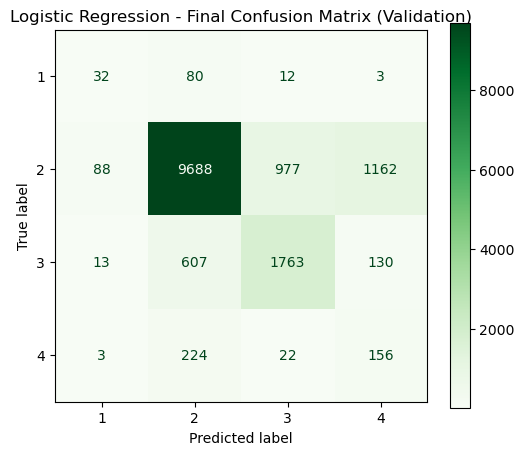

In [8]:
cm = confusion_matrix(y_val, final_pred, labels=[1, 2, 3, 4])

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 2, 3, 4])
disp.plot(cmap="Greens", ax=ax, values_format="d")
ax.set_title("Logistic Regression - Final Confusion Matrix (Validation)")
plt.show()

In [9]:
import joblib

model_path = MODELS_DIR / "logistic_regression_model.pkl"

joblib.dump(final_model, model_path)

print("Logistic Regression model saved to:")
print(model_path)

Logistic Regression model saved to:
E:\DataMining_Group32\models\logistic_regression_model.pkl
